# Lending Game — Part 11: Improving our rule for Round 2

Part 9 replayed every rule on the real Round 1 market and Part 10 identified the competitors' rules.
Three facts drive this part:

* **The Round 1 profit came from the uncontested applicants** (20%: no competitor offer, or only
  fixed quotes of 91.99% / 97.89%). A flat 89.5% quote (R8) would have made €119M against our
  €35M with R4.
* **Each competitor slot is a mixture of four teams**, drawn at random for each loan. One team per
  slot never offered: they alone create the safe uncontested pool. The risky pool comes from real
  pricing choices (high quotes and cutoffs).
* **Every team has now seen its diagnostic file**, so the pool may shrink, and other teams may quote
  just under 90%.

**R8 is not a candidate for the submission.** It ignores risk entirely, which makes no economic
sense; it stays in the tables as a sanity check.

**What this notebook does:**

1. **Four-team scenarios.** Each scenario draws four team rules per competitor slot from a library
   of team types (never offers, pricing curve, cutoff, high quote, flat quote, copies of our Round 1
   R4 and R4|R8), with parameters drawn from a prior. Each applicant then gets one team per slot at
   random, as in the game.
2. **Tuning.** Rules are tuned on Part 10's empirical Round 1 scenario and its stresses (on half A
   of the Round 1 applicants), together with four-team mixtures on the 80,000 training loans.
3. **Rules.**
   * the Round 1 rules, kept fixed: R4, R7, R8, R4|R8 11.1% and R8|R4 11.1%;
   * R4 re-tuned with a constant (step), linear or cubic margin inside each bin, without forcing it
     to increase with risk;
   * R7 re-tuned;
   * R4|R8 hybrids with a tuned switch point and quote;
   * R8 re-tuned, as a sanity check.
4. **Stress tests on data no rule was tuned on:**
   * the Part 7 scenarios;
   * held-out four-team mixtures;
   * Part 10's empirical stresses on half B of Round 1: no-offers and high quotes cut by 25%, 50%
     and 100%, high quotes at 85–90%, cheaper curves, never-offer teams starting to offer, and
     competitors copying R4 or R4|R8.
5. **Round 1:** the exact replay of every rule.
6. **Retraining on 200k loans** and a calibration check above 11%.
7. **The choice**, with the Part 7 criteria (regret, worst case, weighted profit), the empirical
   scenario weighted most.

**Profits are per 100,000 applicants** (the size of a round), so populations of different sizes
are comparable. The code is in `src/round_2_rule.py`.

## 0. Setup

In [1]:
import sys
sys.path.append("..")  # make src/ importable from analysis/

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import FIGURES_DIR
from src.pricing_rules import bootstrap_diff
from src import round_2_rule as r2
from src import round_1_competitors_rules as crr
from src.round_1_replay import market_situation, risk_band, SITUATIONS
from src import model_plots as mp

mp.set_style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)


def save(fig, name):
    # Save a figure for the Part 11 report.
    fig.savefig(FIGURES_DIR / name, dpi=150, bbox_inches="tight")


def money(df, digits=1):
    # Display a table of euros in millions.
    return df.style.format(lambda v: f"{v / 1e6:+.{digits}f}M" if pd.notna(v) else "")


pops = r2.load_populations()
display(pd.Series({k: len(v) for k, v in pops.items()}, name="applicants").to_frame().T)
fixed_rules = r2.round1_rules(pops["train"])
edges = r2.r4_edges()
print("R4 decile edges (p_own):", np.round(100 * edges, 1))

,train,validation,round1,round1_A,round1_B
applicants,80000,20000,100000,50000,50000


R4 decile edges (p_own): [ 1.2  2.8  4.5  6.4  8.7 11.1 13.3 15.4 20.6]


**Check the fast evaluator.** Tuning prices thousands of rules in dozens of markets, so
`market_profit` computes only our expected profit, with the same choice rule as
`src/simulator.py`. It must reproduce our Round 1 profit to the euro, and `simulate_market` in
expected mode on a four-team market where some of our rates tie with a competitor's.

In [2]:
from src.simulator import simulate_market

r1 = pops["round1"]
exact = r2.make_market(r1["r1"], r1["r2"], r1["default"], pref=r1["pref"])
print(f"R4 on the real Round 1 market: {r2.market_profit(exact, fixed_rules['R4 (Round 1)'](r1)).sum():,.0f} EUR "
      f"(course: {r1['profit'].sum():,.0f})")

tr = pops["train"]
c1, c2, _ = r2.draw_mixture(tr, "round 2", seed=3)
ours = r2.rule_high_quote(tr, 0.85).to_numpy()
ours[:100] = c1[:100]                       # force exact ties with lender 1
fast = r2.market_profit(r2.make_market(c1, c2, tr["default"]), ours).sum()
slow = simulate_market(np.column_stack([c1, c2, ours]), tr["default"].to_numpy())[1].loc[3, "total_profit"]
print(f"four-team market: fast {fast:,.2f} EUR, simulator {slow:,.2f} EUR")

R4 on the real Round 1 market: 35,004,134 EUR (course: 35,004,136)
four-team market: fast 39,908,219.62 EUR, simulator 39,908,219.62 EUR


**Both checks pass:** R4's Round 1 profit is reproduced to €2 (rounding of the rates in the course
file), and the fast evaluator matches the simulator to the cent on a four-team market with ties.

## 1. Four rules per competitor slot

`draw_mixture` draws, **for each slot, four teams** from a prior over team types, then gives each
applicant one team per slot at random. The competitors' default probabilities are our
reconstructed lender 1 and 2 models (`p_lender1`, `p_lender2`), which see the competitors'
signals. So the winner's curse is kept: a team's no-offers and high quotes fall more often on
borrowers who default.

| team type | rule (on the team's own $p$) | Round 1 team (Part 10) |
|---|---|---|
| never | never offers | 1A, 2A |
| curve | $be(p) + m_{safe}$ below a switch (8–12.5%), $+ m_{risky}$ above | 1C, 2C, 2D |
| cutoff | a curve, no offer from 10–20% | 1D |
| high quote | a curve, then a fixed quote $q$ from 5–12.5% | 1B, 2B |
| flat quote | $q$ for everyone (a team copying R8) | — |
| copy R4 | our Round 1 R4 | — |
| copy R4\|R8 | R4 below 11.1%, $q$ above | — |

**Three priors over the teams:**

* **round 1**: one never-offer team, one high-quote team and two curve or cutoff teams per slot, as
  in Part 10;
* **round 2** (our central guess): fewer never-offer teams (8%), some copycats of R4, R8 and
  R4|R8 (10% each), and high quotes undercut down to 80%;
* **gap closed**: nobody refuses, every high quote is at 80–90%, and curves are cheaper. The
  uncontested pool is gone.

In [3]:
display(pd.DataFrame({k: v["teams"] for k, v in r2.PRIORS.items()}).fillna(0).T.style.format("{:.0%}"))
for prior in r2.PRIORS:
    _, _, teams = r2.draw_mixture(tr, prior, seed=0)
    print(f"one draw, prior '{prior}':")
    display(r2.describe_teams(teams))

,never,high quote,curve,cutoff,flat quote,copy R4,copy R4|R8
round 1,25%,25%,25%,25%,0%,0%,0%
round 2,8%,17%,30%,15%,10%,10%,10%
gap closed,0%,10%,45%,0%,0%,25%,20%


one draw, prior 'round 1':


,slot 1,slot 2
team 1,"curve, 2.7 pts, 35.0 pts risky","cutoff, 1.5 pts, 20.0 pts risky, cutoff 15.0%"
team 2,"high quote, 2.4 pts, from 12.5%, quote 94.3%","cutoff, 1.7 pts, 35.0 pts risky, cutoff 10.0%"
team 3,never,never
team 4,never,"cutoff, 1.9 pts, 10.0 pts risky, cutoff 12.5%"


one draw, prior 'round 2':


,slot 1,slot 2
team 1,"cutoff, 3.1 pts, 35.0 pts risky, cutoff 15.0%","copy R4|R8, quote 80.3%"
team 2,"curve, 2.9 pts, 20.0 pts risky",copy R4
team 3,never,never
team 4,never,copy R4


one draw, prior 'gap closed':


,slot 1,slot 2
team 1,copy R4,"copy R4|R8, quote 87.3%"
team 2,"curve, 2.6 pts, 35.0 pts risky","curve, 1.4 pts, 35.0 pts risky"
team 3,"curve, 2.2 pts, 20.0 pts risky","copy R4|R8, quote 85.4%"
team 4,"curve, 2.1 pts, 35.0 pts risky","curve, 1.6 pts, 10.0 pts risky"


**Do the mixtures look like Round 1?** We compare the market situation of each applicant (no
competitor offer / only quotes of 90% or more / contested) by risk band. On the left is the real
Round 1 market; the other columns average 30 draws of each prior on the training loans.

In [4]:
def situation_shares(r1_, r2_, p):
    frame = pd.DataFrame({"r1": r1_, "r2": r2_, "p_own": p})
    shares = pd.crosstab(risk_band(frame), market_situation(frame), normalize="index")
    return shares.reindex(columns=SITUATIONS, fill_value=0.0)[SITUATIONS[:2]].sum(axis=1)

uncontested = {"Round 1 (real)": situation_shares(r1["r1"], r1["r2"], r1["p_own"])}
for prior in r2.PRIORS:
    draws = [situation_shares(*r2.draw_mixture(tr, prior, seed=s)[:2], tr["p_own"].to_numpy())
             for s in range(30)]
    uncontested[f"mixtures: {prior}"] = pd.concat(draws, axis=1).mean(axis=1)
uncontested = pd.DataFrame(uncontested)
display(uncontested.style.format("{:.1%}", na_rep=""))

,Round 1 (real),mixtures: round 1,mixtures: round 2,mixtures: gap closed
p_own,,,,
< 2.75%,6.3%,5.5%,0.4%,0.0%
2.75-4.5%,7.4%,6.3%,0.4%,0.0%
4.5-8%,11.2%,10.6%,0.6%,0.0%
8-11%,18.8%,20.1%,1.3%,0.0%
11-15%,28.1%,34.8%,3.1%,0.0%
15-20%,34.7%,41.6%,4.0%,0.0%
20-30%,45.9%,49.9%,5.2%,0.0%
>= 30%,49.4%,52.5%,5.7%,0.0%


**Findings.**

* **The "round 1" prior reproduces the Round 1 market:** 5.5% uncontested among the safest
  applicants (real: 6.3%), rising to about half above 20% risk (real: 49%). It is slightly too
  generous between 11% and 20% risk.
* **The "round 2" prior almost removes the pool as measured here** (0.4–5.7%). This counts only
  quotes of 90% or more, while the round 2 copycats quote 80–90%: a high quote below theirs still
  finds risky applicants to win (section 6).
* **"gap closed" leaves nobody uncontested**, by construction.

**The eight teams inferred in Part 10, rebuilt as rules.** The random priors above are one test.
A sharper one uses the Round 1 teams themselves (Part 10, section 3.3), in terms of the same team
types:

| slot | team | rule |
|---|---|---|
| lender 1 | 1A | never offers |
| | 1B | 2 points over break-even, 91.99% from $\hat p = 7\%$ |
| | 1C | 2 points, 8 points from 8%, no offer from 17.5% |
| | 1D | 2 points, 4.5 points from 6%, no offer from 20% |
| lender 2 | 2A | never offers |
| | 2B | 2.5 points, 97.89% from 10% |
| | 2C | 3 points, 8 points from 10% |
| | 2D | 2.4 points, 36 points from 10% |

**Check on the 20,000 validation loans** (never used in tuning; 10 random assignments of teams to
applicants). If the rebuilt teams are right, they should reproduce the Round 1 market: the shares
of uncontested applicants by band, and each Round 1 rule's real profit.

In [5]:
p10 = r2.part10_variants()["Part 10 teams"]
val = pops["validation"]
sim = [situation_shares(*r2.teams_market(val, p10, j), val["p_own"].to_numpy()) for j in range(10)]
display(pd.DataFrame({"Round 1 (real)": uncontested["Round 1 (real)"],
                      "Part 10 teams (validation)": pd.concat(sim, axis=1).mean(axis=1)})
        .style.format("{:.1%}").set_caption("Share of uncontested applicants by band"))

check = {}
for name, rule in fixed_rules.items():
    rv = np.asarray(rule(val), dtype=float)
    sim_profit = np.mean([5 * r2.market_profit(r2.make_market(*r2.teams_market(val, p10, j), val["default"]), rv).sum()
                          for j in range(10)])
    check[name] = {"real Round 1": r2.market_profit(exact, np.asarray(rule(r1), dtype=float)).sum(),
                   "Part 10 teams, validation (per 100k)": sim_profit}
display(money(pd.DataFrame(check).T))

,Round 1 (real),Part 10 teams (validation)
p_own,,
< 2.75%,6.3%,6.3%
2.75-4.5%,7.4%,6.5%
4.5-8%,11.2%,9.8%
8-11%,18.8%,19.2%
11-15%,28.1%,26.9%
15-20%,34.7%,31.4%
20-30%,45.9%,39.8%
>= 30%,49.4%,45.6%


,real Round 1,"Part 10 teams, validation (per 100k)"
R4 (Round 1),+35.0M,+31.5M
R7 (Part 6),+24.3M,+23.2M
R8 89.5% (Part 9),+118.9M,+113.8M
R4|R8 11.1% (Part 9),+77.5M,+74.3M
R8|R4 11.1% (Part 9),+76.4M,+71.0M


**Findings.**

* **The eight rebuilt teams reproduce the Round 1 market on loans they never saw:** uncontested
  shares within 1.5 points below 20% risk, 4–6 points too low above (39.8% vs 45.9% at 20–30%).
* **Every Round 1 rule's profit is reproduced within €1–5M** (R4: €31.5M vs €35.0M; R8: €113.8M vs
  €118.9M), always slightly below the real figure. Part 10's description of the teams is
  therefore accurate enough to build scenarios on.

## 2. The tuning scenarios

| group | scenarios | population | weight |
|---|---|---|---|
| empirical | Part 10's empirical Round 1 scenario (3 resamplings) | Round 1, half A | 30% |
| empirical stress | never-offer teams offer · no-offers & high quotes −50% · high quotes at 85% · curves −1 pt · no-offers & high quotes −100% (2 resamplings each) | Round 1, half A | 30% |
| mixtures | 30 draws of the "round 2" prior | 80,000 training loans | 25% |
| | 20 draws of the "gap closed" prior | 80,000 training loans | 15% |

The empirical scenarios carry 60% of the weight, as the guidelines ask. **Half B of the Round 1
applicants and the 20,000 validation loans are never used in tuning**; they are kept for the stress
tests (section 7).

In [6]:
t0 = time.time()
tuning = r2.tuning_scenarios(pops)
names = list(dict.fromkeys(s["name"] for s in tuning))
TUNING_WEIGHTS = pd.Series([s["weight"] for s in tuning], index=[s["name"] for s in tuning]).groupby(level=0, sort=False).sum()
print(f"{len(tuning)} markets in {time.time() - t0:.0f}s")
display(TUNING_WEIGHTS.to_frame("weight").T.style.format("{:.1%}"))

fixed_tuning = pd.DataFrame({name: r2.scenario_means(r2.population_rates(rule, pops, ["round1_A", "train"]), tuning)
                             for name, rule in fixed_rules.items()}).T
fixed_tuning["weighted"] = fixed_tuning[names].mul(TUNING_WEIGHTS[names]).sum(axis=1)
display(money(fixed_tuning))

63 markets in 1s


,Round 1 empirical,never-offer teams offer,no-offers & high quotes -50%,high quotes at 85%,curves -1 pt,no-offers & high quotes -100%,mixture round 2,mixture gap closed
weight,30.0%,6.0%,6.0%,6.0%,6.0%,6.0%,25.0%,15.0%


,Round 1 empirical,never-offer teams offer,no-offers & high quotes -50%,high quotes at 85%,curves -1 pt,no-offers & high quotes -100%,mixture round 2,mixture gap closed,weighted
R4 (Round 1),+33.4M,+17.8M,+16.2M,+33.4M,+31.4M,+5.3M,+29.6M,+17.9M,+26.3M
R7 (Part 6),+23.6M,+13.6M,+13.0M,+23.2M,+21.6M,+6.2M,+21.7M,+14.9M,+19.4M
R8 89.5% (Part 9),+116.8M,+23.8M,+29.4M,+56.4M,+117.3M,+0.0M,+23.0M,+0.4M,+54.5M
R4|R8 11.1% (Part 9),+75.5M,+24.5M,+21.8M,+30.1M,+74.4M,+3.7M,+20.3M,+4.1M,+37.6M
R8|R4 11.1% (Part 9),+74.6M,+17.0M,+23.9M,+59.6M,+74.3M,+1.5M,+32.3M,+14.3M,+43.2M


**Findings: the Round 1 rules on the tuning scenarios.**

* **R4 holds up when competitors adapt** (€5–33M), but earns only **€5.3M** once no-offers and
  high quotes disappear.
* **R8 is all or nothing:** €117M on the Round 1 scenario, **€0.0–0.4M** when the pool is gone.
* **Part 9's R4|R8 11.1%** keeps €75M on Round 1 but falls to €4M in the gap-closed mixtures, less
  than R4.
* **No Round 1 rule is good everywhere**, which is what the rest of this part tries to fix.

## 3. Why the competitive rules are tuned on contested markets

A first attempt tuned R4's margin per bin on the **full** tuning objective. **Every bin's margin
ran to the top of the grid (40 points)**: as long as some uncontested pool survives, a higher
rate earns more in every bin, even on 1% risk borrowers. The "re-tuned R4" became a disguised
high quote, which is R8 again.

So the competitive rules are tuned only on the **contested** markets, where the uncontested pool
is gone: "no-offers & high quotes −100%" (empirical, half A) and the "gap closed" mixtures, 50%
each. They then answer one clear question: **how should we price when there is competition?**
Where to quote high instead is decided separately (section 6), with a criterion that guards
against R8.

In [7]:
full_step = r2.fit_bin_poly(pops, tuning, degree=0, progress=False)
display(r2.poly_table(full_step, 1).rename(columns={"x = -1.0": "margin (pts)"}).T
        .style.format("{:.1f}").set_caption("R4 step tuned on the FULL objective: every bin at the 40-point cap"))

contested = r2.reweight(tuning, r2.CONTESTED)
print(f"contested tuning set: {len(contested)} markets")

,bin 1 (0.0-1.2%),bin 2 (1.2-2.7%),bin 3 (2.8-4.5%),bin 4 (4.5-6.4%),bin 5 (6.5-8.7%),bin 6 (8.7-11.1%),bin 7 (11.1-13.3%),bin 8 (13.3-15.4%),bin 9 (15.4-20.5%),bin 10 (20.6-44.3%)
margin (pts),40.0,40.0,40.0,40.0,40.0,35.0,33.0,40.0,40.0,40.0


contested tuning set: 22 markets


## 4. R4 with a constant, linear or cubic margin in each bin

R4's ten decile bins are kept, so the results stay comparable with Round 1. Inside each bin the
margin over break-even is a polynomial in the applicant's position $x \in [-1, 1]$ in the bin:

$$r = be(p) + \sum_{j=0}^{d} c_{b,j}\,x^j, \qquad d = 0 \text{ (step)},\ 1 \text{ (linear)},\ 3 \text{ (cubic)}.$$

* **No monotonicity:** each bin is free, and the margin may fall with risk. The Round 1 R4 was
  forced to increase (isotonic smoothing).
* **Tuning by coordinate descent:** for each coefficient in turn, every value of its grid is tried
  in all bins at once and each bin keeps its best value. Bins are independent (an applicant's
  choice depends only on their own offers), so one evaluation prices all ten bins. The linear fit
  starts from the step solution and the cubic from the linear one, so the in-sample objective can
  only go up.

In [8]:
fits = {}
fits["step"] = r2.fit_bin_poly(pops, contested, degree=0)
fits["linear"] = r2.fit_bin_poly(pops, contested, degree=1, start=fits["step"]["coefs"])
fits["cubic"] = r2.fit_bin_poly(pops, contested, degree=3, start=fits["linear"]["coefs"])
poly_rules = {f"R4-{k}": r2.make_poly_rule(f) for k, f in fits.items()}

obj = pd.Series({"R4 (Round 1)": r2.objective(fixed_rules["R4 (Round 1)"], contested, pops),
                 **{k: f["objective"] for k, f in zip(poly_rules, fits.values())}})
display(money(obj.to_frame("contested tuning objective (in sample)").T, 2))
for k, f in fits.items():
    display(r2.poly_table(f).style.format("{:.2f}").set_caption(f"R4-{k}: margin (points) at five positions in each bin"))

  degree 0, sweep 1: objective 12,905,235 (5s)
  degree 1, sweep 1: objective 12,928,322 (6s)
  degree 1, sweep 2: objective 12,943,663 (13s)
  degree 1, sweep 3: objective 12,943,663 (19s)
  degree 3, sweep 1: objective 12,985,086 (8s)
  degree 3, sweep 2: objective 12,992,905 (17s)
  degree 3, sweep 3: objective 12,992,905 (25s)


,R4 (Round 1),R4-step,R4-linear,R4-cubic
contested tuning objective (in sample),+11.57M,+12.91M,+12.94M,+12.99M


,x = -1.0,x = -0.5,x = +0.0,x = +0.5,x = +1.0
bin 1 (0.0-1.2%),3.00,3.00,3.00,3.00,3.00
bin 2 (1.2-2.7%),2.75,2.75,2.75,2.75,2.75
bin 3 (2.8-4.5%),2.25,2.25,2.25,2.25,2.25
bin 4 (4.5-6.4%),3.25,3.25,3.25,3.25,3.25
bin 5 (6.5-8.7%),3.25,3.25,3.25,3.25,3.25
bin 6 (8.7-11.1%),9.00,9.00,9.00,9.00,9.00
bin 7 (11.1-13.3%),14.50,14.50,14.50,14.50,14.50
bin 8 (13.3-15.4%),14.50,14.50,14.50,14.50,14.50
bin 9 (15.4-20.5%),15.00,15.00,15.00,15.00,15.00
bin 10 (20.6-44.3%),17.00,17.00,17.00,17.00,17.00


,x = -1.0,x = -0.5,x = +0.0,x = +0.5,x = +1.0
bin 1 (0.0-1.2%),3.00,3.00,3.00,3.00,3.00
bin 2 (1.2-2.7%),2.75,2.75,2.75,2.75,2.75
bin 3 (2.8-4.5%),2.25,2.25,2.25,2.25,2.25
bin 4 (4.5-6.4%),3.25,3.25,3.25,3.25,3.25
bin 5 (6.5-8.7%),3.25,3.25,3.25,3.25,3.25
bin 6 (8.7-11.1%),10.00,9.50,9.00,8.50,8.00
bin 7 (11.1-13.3%),16.00,15.50,15.00,14.50,14.00
bin 8 (13.3-15.4%),15.00,14.50,14.00,13.50,13.00
bin 9 (15.4-20.5%),15.50,15.25,15.00,14.75,14.50
bin 10 (20.6-44.3%),17.00,17.00,17.00,17.00,17.00


,x = -1.0,x = -0.5,x = +0.0,x = +0.5,x = +1.0
bin 1 (0.0-1.2%),3.00,3.00,3.00,3.00,3.00
bin 2 (1.2-2.7%),3.25,2.88,2.75,2.88,3.25
bin 3 (2.8-4.5%),2.25,2.25,2.25,2.25,2.25
bin 4 (4.5-6.4%),3.25,3.25,3.25,3.25,3.25
bin 5 (6.5-8.7%),3.00,3.38,3.50,3.38,3.00
bin 6 (8.7-11.1%),10.00,9.50,9.00,8.50,8.00
bin 7 (11.1-13.3%),16.00,15.50,15.00,14.50,14.00
bin 8 (13.3-15.4%),14.50,14.38,14.00,13.38,12.50
bin 9 (15.4-20.5%),14.50,15.00,15.00,14.50,13.50
bin 10 (20.6-44.3%),19.00,17.25,17.00,16.75,15.00


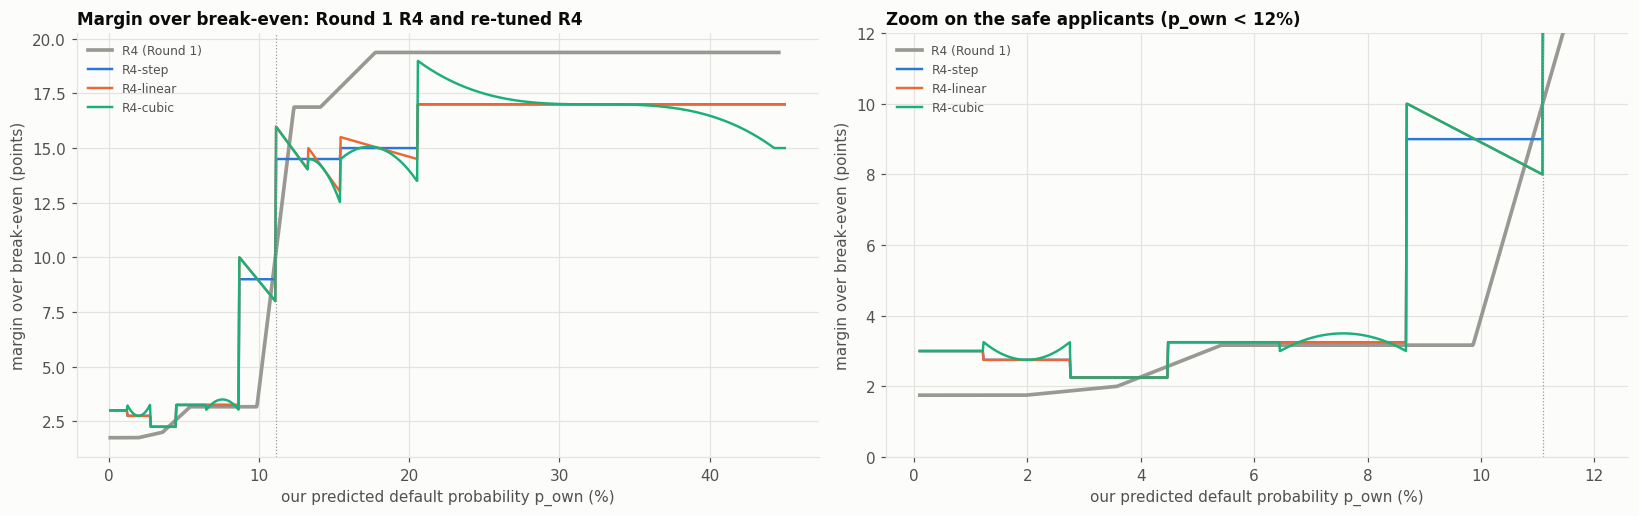

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
curves = {"R4 (Round 1)": fixed_rules["R4 (Round 1)"], **poly_rules}
r2.plot_margin_curves(curves, axes[0], p_max=0.45, title="Margin over break-even: Round 1 R4 and re-tuned R4")
r2.plot_margin_curves(curves, axes[1], p_max=0.12, title="Zoom on the safe applicants (p_own < 12%)")
axes[1].set_ylim(0, 12)
fig.tight_layout()
save(fig, "fig26_r4_margin_curves.png")
plt.show()

**Findings: the re-tuned R4.**

* **On contested markets the re-tuned margins beat R4 by €1.3–1.4M** (in sample: €12.9–13.0M
  against €11.6M per 100k).
* **The step is as good as the linear and cubic shapes:** linear adds €0.04M and cubic €0.09M, in
  sample only. Inside a decile the margin barely needs to move.
* **The new margins are higher on the safest applicants** (3 points below 1.2% risk, against R4's
  1.75), as Part 9 found in hindsight.
* **Between 8.7% and 11% they jump earlier** (9 points, where R4 still charged 3.2).
* **Above 12% they are lower:** 14.5–17 points, against R4's 16.9–19.4. This differs from Part 9's
  hindsight on Round 1 (25–32 points), because in these contested markets the competitors lend to
  risky applicants at moderate rates.
* **Without the monotonicity constraint the curve is not monotone:** 3.0 → 2.75 → 2.25 → 3.25
  points over the first four bins. The dip near 3–4% risk is real in the tuning data, but small.

## 5. R7 re-tuned, on the same contested markets

In [10]:
best7, table7 = r2.tune_r7(pops, contested, pops["train"])
print("best R7:", best7)
display(money(table7.sort_values("objective", ascending=False).head(8).set_index(["q", "a", "delta"]), 2))
rule_r7 = r2.make_r7_rule(pops["train"], **best7)

best R7: {'q': 0.25, 'a': 0.6, 'delta': -0.03}


**Findings: R7 re-tuned.** It undercuts the cheaper competitor's predicted break-even (25th
percentile) by 3 points, with a strong risk adjustment ($a = 0.6$). **$a = 0.6$ is the edge of
the grid**, so a larger adjustment might do slightly better. Its contested objective (€11.95M) is
below the re-tuned R4 (€12.9M), so its extra machinery still does not pay.

## 6. High quotes: R8 (sanity check) and the R4/R8 hybrids

**R8 re-tuned.** One flat quote for everyone, on the full tuning objective:

In [11]:
flat = r2.flat_quote_objective(pops, tuning, edges)
total_flat = flat.sum()
best_q = float(total_flat.idxmax())
print(f"best flat quote: {best_q:.1%}, tuning objective {total_flat.max() / 1e6:+.1f}M")
display(money(total_flat.loc[[0.6, 0.7, 0.75, 0.78, 0.8, 0.82, 0.85, 0.88, 0.895, 0.9, 0.95]].to_frame("objective").T))
rule_r8 = lambda data: r2.rule_high_quote(data, best_q)

best flat quote: 80.0%, tuning objective +67.7M


quote,0.600000,0.700000,0.750000,0.780000,0.800000,0.820000,0.850000,0.880000,0.895000,0.900000,0.950000
objective,+50.2M,+59.6M,+64.5M,+67.2M,+67.7M,+66.4M,+59.7M,+55.3M,+54.5M,+49.8M,+40.9M


**Findings: R8 re-tuned.** Against our Round 2 priors the best flat quote falls from 89.5% to
**80%**, the bottom of the copycats' range. It undercuts every assumed high quote, so this level
reflects our assumptions. It stays a sanity check.

**The hybrids.** A competitive rule (the re-tuned R4) on one side of a switch point $s$ and a flat
quote $q$ on the other:

* **R4|R8**: the high quote above $s$, on risky applicants;
* **R8|R4**: the high quote below $s$, on safe applicants.

On weighted profit, more high quote is always better, as in Part 9. So the switch and the quote are
chosen with the **Part 7 main criterion, minimax regret across the tuning scenarios**: the hybrid
that loses the least, in its worst scenario, compared with the best hybrid of that scenario.

In [12]:
t0 = time.time()
grid_lin = r2.hybrid_grid(poly_rules["R4-linear"], pops, tuning)
print(f"{len(grid_lin)} hybrids in {time.time() - t0:.0f}s")
best_any, grid_lin = r2.select_hybrid(grid_lin, TUNING_WEIGHTS.to_dict())
print("smallest max regret, both directions:", best_any)
cols = names + ["max regret", "weighted"]
display(money(grid_lin.sort_values("max regret")[cols].head(6)))
display(money(grid_lin.loc[["none"]][cols]))

649 hybrids in 131s
smallest max regret, both directions: {'high_side': 'above', 'p_switch': 0.012217877363987672, 'quote': 0.82, 'max regret': 9638897.222222231, 'weighted': 64499389.182433486}


,,,Round 1 empirical,never-offer teams offer,no-offers & high quotes -50%,high quotes at 85%,curves -1 pt,no-offers & high quotes -100%,mixture round 2,mixture gap closed,max regret,weighted
side,switch,quote,,,,,,,,,,
none,nan,nan,+31.4M,+17.4M,+16.2M,+31.5M,+29.0M,+6.4M,+28.9M,+19.5M,+83.2M,+25.6M


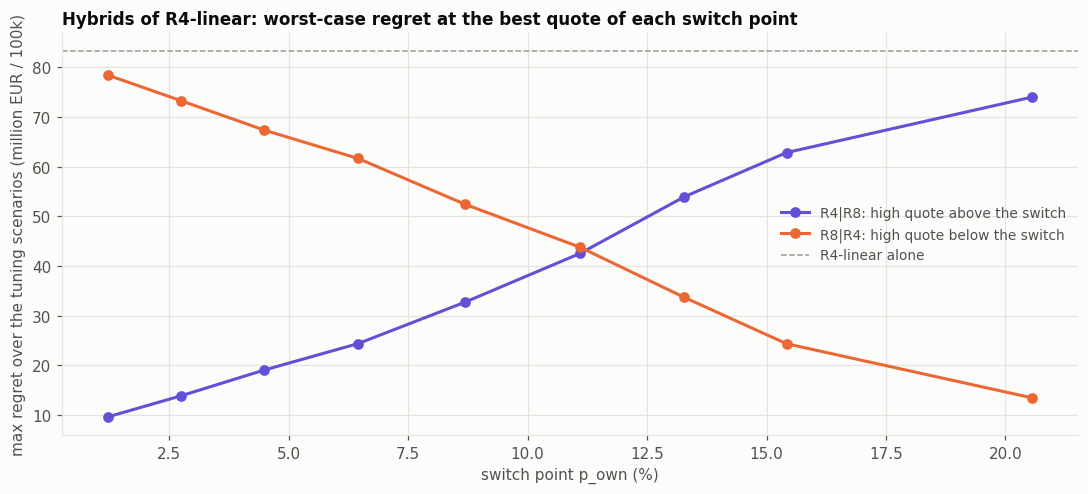

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.6))
for color, side, label in ((mp.SINGLE_COLOR, "above", "R4|R8: high quote above the switch"),
                           ("#eb6834", "below", "R8|R4: high quote below the switch")):
    g = grid_lin.loc[side].groupby(level="switch")["max regret"].min()
    ax.plot(100 * g.index, g / 1e6, "o-", color=color, label=label)
ax.axhline(grid_lin.loc[grid_lin.index.get_level_values("side") == "none", "max regret"].iloc[0] / 1e6, color=mp.REFERENCE, ls="--", lw=1,
           label="R4-linear alone")
ax.set_xlabel("switch point p_own (%)")
ax.set_ylabel("max regret over the tuning scenarios (million EUR / 100k)")
ax.set_title("Hybrids of R4-linear: worst-case regret at the best quote of each switch point")
ax.legend(labelcolor=mp.INK_SECONDARY)
fig.tight_layout()
save(fig, "fig27_hybrid_regret.png")
plt.show()

**R8 again.** Even with minimax regret, the best hybrid of either direction is the one that quotes
high to almost everyone. The reason is an asymmetry:

* where an uncontested pool survives, a rule without a high quote gives up most of it, tens of
  millions of euros;
* where the pool is gone, quoting high costs only the thin contested margin, a few million euros.

**Our decision:** R8 is not a candidate, and neither is a hybrid that quotes high to the safe
majority. **A high quote is eligible only for risky applicants** ($p_{own} \ge 8.7\%$, the
R4|R8 direction). That is where Part 10 found the pool comes from real pricing choices (high-quote
and cutoff teams), which are likely to persist. Within that family, the switch and the quote are
chosen by minimax regret, for each R4 variant.

In [14]:
RISKY_SWITCHES = [s for s in edges if s >= 0.086]
hybrid_rules, hybrid_choice = {}, {}
for name, base in poly_rules.items():
    grid = r2.hybrid_grid(base, pops, tuning, switches=RISKY_SWITCHES, sides=("above",))
    best, _ = r2.select_hybrid(grid, TUNING_WEIGHTS.to_dict(), side="above")
    hybrid_choice[f"{name}|R8"] = best
    hybrid_rules[f"{name}|R8"] = r2.make_hybrid_rule(base, best["p_switch"], best["quote"], "above")
display(pd.DataFrame(hybrid_choice).T.style.format({"p_switch": "{:.1%}", "quote": "{:.1%}",
                                                    "max regret": "{:,.0f}", "weighted": "{:,.0f}"}))

,high_side,p_switch,quote,max regret,weighted
R4-step|R8,above,8.7%,82.0%,"7,076,858","52,450,613"
R4-linear|R8,above,8.7%,82.0%,"7,076,858","52,450,613"
R4-cubic|R8,above,8.7%,82.0%,"7,076,858","52,481,897"


**Findings: the hybrids restricted to risky applicants.**

* **All three R4 variants choose the same hybrid:** the high quote from **$p_{own} = 8.7\%$**
  (the 6th decile edge, one decile lower than Part 9's 11.1%) at **82%**.
* **Step and linear give the identical rule:** they only differ above 8.7%, where the quote
  replaces them. The cubic differs slightly in two safe bins.
* **The 82% quote sits just above the bottom of the assumed range of rival high quotes (80–98%).**
  It is chosen to stay below most of them while charging as much as possible. Section 7b tests
  this choice.

## 7. Stress tests on held-out data

**Every rule, with its parameters fixed, against scenarios it was never tuned on:**

| group | scenarios | population |
|---|---|---|
| round 1 | the real Round 1 offers and borrower types ("Round 1 exact (B)") | Round 1, half B |
| empirical | Part 10's empirical scenario and 11 stresses (3 resamplings each): no-offers & high quotes −25/−50/−100%, high quotes at 90/88/85%, curves −1/−2/−3 pts, never-offer teams offer (also with high quotes at 85%) | Round 1, half B |
| mixtures | 30 new draws of each prior (round 1, round 2, gap closed) | 20,000 validation loans |
| Part 10 teams | the eight inferred teams; never-offer teams offer; high quotes at 85%; never-offer teams copy R4\|R8 at 85% (10 assignments each) | validation loans |
| Part 7 | T1–T6, H1/H3/H5, A05, A13, K50, IPUB, IFULL; S_R4 = both competitors copy R4; S_R4\|R8 = both copy R4\|R8 11.1% at 89.5% | validation loans |

**Criteria** (Part 7), on the rules eligible for submission:

* **max regret** (the main criterion), against the best eligible rule of each scenario;
* **worst-case profit**;
* **weighted profit**, with weights:
  * 3 for Round 1 exact, the empirical scenario and the round 2 mixtures;
  * 2 for the gap-closed mixtures and the Part 10 teams;
  * 1 for each empirical stress, each Part 10 variant and the round 1 mixtures;
  * 0.25 for each Part 7 scenario (one rule per slot, the structure that missed Round 1).

  The empirical scenarios carry about 60% of the weight.

R8 and R8|R4 are shown for reference only and do not set the regret.

In [15]:
t0 = time.time()
stress = r2.stress_scenarios(pops)
print(f"{len(stress)} held-out markets in {time.time() - t0:.0f}s")

all_rules = {**fixed_rules, **poly_rules, "R7 (re-tuned)": rule_r7, **hybrid_rules,
             "R8 (re-tuned)": rule_r8}
t0 = time.time()
scores = r2.score_rules(all_rules, stress, pops)
print(f"scored {len(all_rules)} rules in {time.time() - t0:.0f}s")
profits = r2.profit_table(scores)
REFERENCE_ONLY = ["R8 89.5% (Part 9)", "R8|R4 11.1% (Part 9)", "R8 (re-tuned)"]
ELIGIBLE = [r for r in all_rules if r not in REFERENCE_ONLY]
crit, regret = r2.criteria(profits, ELIGIBLE)
display(money(crit.drop(columns=["worst scenario", "max-regret scenario"])))
display(crit[["worst scenario", "max-regret scenario"]])

183 held-out markets in 2s
scored 13 rules in 4s


,worst-case profit,max regret,weighted profit,vs R4: no-offers & high quotes -100%,vs R4: never-offer teams offer,vs R4: mix: gap closed
rule,,,,,,
R4-step|R8,+0.3M,+15.7M,+56.7M,-1.3M,+8.0M,-2.4M
R4-linear|R8,+0.3M,+15.7M,+56.7M,-1.3M,+8.0M,-2.4M
R4-cubic|R8,+0.2M,+15.7M,+56.7M,-1.3M,+8.0M,-2.4M
R4|R8 11.1% (Part 9),+0.3M,+105.9M,+43.6M,-1.1M,+7.2M,-12.5M
R4 (Round 1),-2.0M,+119.3M,+25.9M,+0.0M,+0.0M,+0.0M
R7 (re-tuned),-1.2M,+120.3M,+26.3M,-0.1M,-0.3M,+0.8M
R4-step,-2.5M,+125.0M,+24.4M,+0.3M,-1.3M,+1.5M
R4-cubic,-2.7M,+125.0M,+24.4M,+0.3M,-1.3M,+1.5M
R4-linear,-2.6M,+125.2M,+24.4M,+0.3M,-1.3M,+1.5M


,worst scenario,max-regret scenario
rule,,
R4-step|R8,A13,S_R4
R4-linear|R8,A13,S_R4
R4-cubic|R8,A13,S_R4
R4|R8 11.1% (Part 9),A13,S_R4|R8
R4 (Round 1),IFULL,S_R4|R8
R7 (re-tuned),IFULL,S_R4|R8
R4-step,IFULL,S_R4|R8
R4-cubic,IFULL,S_R4|R8
R4-linear,IFULL,S_R4|R8


In [16]:
groups = scores.drop_duplicates("scenario").set_index("scenario")["group"]
for g in ["round 1", "empirical", "mixture", "part 10 teams", "part 7"]:
    cols_g = [c for c in profits.columns if groups[c] == g]
    display(money(profits[cols_g]).set_caption(f"Profit per 100k applicants: {g} scenarios"))

scenario,Round 1 exact (B)
rule,
R4 (Round 1),+35.9M
R7 (Part 6),+25.1M
R8 89.5% (Part 9),+121.5M
R4|R8 11.1% (Part 9),+80.1M
R8|R4 11.1% (Part 9),+77.3M
R4-step,+33.3M
R4-linear,+33.2M
R4-cubic,+33.4M
R7 (re-tuned),+36.7M


scenario,Round 1 empirical,no-offers & high quotes -25%,no-offers & high quotes -50%,no-offers & high quotes -100%,high quotes at 90%,high quotes at 88%,high quotes at 85%,curves -1 pt,curves -2 pts,curves -3 pts,never-offer teams offer,never-offer teams offer + HQ 85%
rule,,,,,,,,,,,,
R4 (Round 1),+36.8M,+26.6M,+17.9M,+4.6M,+36.7M,+36.7M,+36.6M,+35.1M,+33.2M,+31.9M,+19.2M,+19.0M
R7 (Part 6),+26.2M,+19.5M,+13.6M,+4.9M,+26.1M,+26.1M,+26.0M,+24.3M,+22.3M,+21.1M,+14.0M,+13.9M
R8 89.5% (Part 9),+123.6M,+69.5M,+30.3M,+0.0M,+96.3M,+79.3M,+57.1M,+123.5M,+123.4M,+123.3M,+26.3M,+0.2M
R4|R8 11.1% (Part 9),+81.9M,+48.0M,+23.7M,+3.5M,+61.1M,+48.6M,+31.9M,+80.3M,+78.9M,+77.9M,+26.4M,+4.0M
R8|R4 11.1% (Part 9),+78.6M,+48.2M,+24.5M,+1.1M,+71.9M,+67.4M,+61.8M,+78.2M,+77.8M,+77.3M,+19.1M,+15.2M
R4-step,+34.6M,+25.1M,+17.1M,+4.8M,+34.4M,+34.4M,+34.4M,+32.2M,+30.5M,+29.4M,+17.8M,+17.7M
R4-linear,+34.6M,+25.1M,+17.1M,+4.9M,+34.5M,+34.4M,+34.4M,+32.2M,+30.4M,+29.3M,+17.8M,+17.7M
R4-cubic,+34.6M,+25.2M,+17.1M,+4.8M,+34.6M,+34.5M,+34.5M,+32.3M,+30.5M,+29.4M,+17.9M,+17.8M
R7 (re-tuned),+38.0M,+27.1M,+17.9M,+4.5M,+37.7M,+37.7M,+37.4M,+35.7M,+33.9M,+32.8M,+18.9M,+18.5M


scenario,mix: round 1,mix: round 2,mix: gap closed
rule,,,
R4 (Round 1),+34.3M,+28.0M,+17.3M
R7 (Part 6),+23.6M,+20.2M,+14.5M
R8 89.5% (Part 9),+122.7M,+27.7M,+0.6M
R4|R8 11.1% (Part 9),+87.5M,+25.9M,+4.7M
R8|R4 11.1% (Part 9),+69.4M,+29.8M,+13.1M
R4-step,+32.4M,+27.2M,+18.7M
R4-linear,+32.4M,+27.2M,+18.7M
R4-cubic,+32.5M,+27.3M,+18.7M
R7 (re-tuned),+35.4M,+28.7M,+18.1M


scenario,Part 10 teams,"Part 10, never-offer teams offer","Part 10, high quotes at 85%","Part 10, never-offer teams copy R4|R8"
rule,,,,
R4 (Round 1),+30.4M,+14.5M,+30.2M,+26.1M
R7 (Part 6),+22.2M,+13.7M,+22.2M,+18.7M
R8 89.5% (Part 9),+111.2M,+22.1M,+51.1M,+22.1M
R4|R8 11.1% (Part 9),+72.4M,+23.5M,+27.9M,+23.5M
R8|R4 11.1% (Part 9),+69.2M,+13.1M,+53.4M,+24.7M
R4-step,+28.5M,+14.3M,+28.3M,+23.8M
R4-linear,+28.5M,+14.3M,+28.3M,+23.8M
R4-cubic,+28.6M,+14.4M,+28.4M,+23.9M
R7 (re-tuned),+31.3M,+15.4M,+31.0M,+25.9M


scenario,T1,T2,T3,T4,T5,T6,H1,H3,H5,A05,A13,K50,IPUB,IFULL,S_R4,S_R4|R8
rule,,,,,,,,,,,,,,,,
R4 (Round 1),+0.5M,+2.6M,+6.7M,+1.3M,+3.2M,+6.5M,+1.5M,+4.0M,+9.2M,+1.4M,+0.1M,+5.2M,+6.0M,-2.0M,+13.8M,+48.1M
R7 (Part 6),-0.5M,+1.7M,+5.9M,+0.2M,+3.0M,+5.8M,+0.9M,+2.8M,+9.3M,+0.4M,-1.1M,+7.2M,+8.5M,-4.6M,+16.4M,+30.0M
R8 89.5% (Part 9),+0.0M,+0.0M,+0.0M,+0.0M,-0.0M,+0.0M,+0.0M,+0.0M,+0.0M,+0.0M,+0.0M,-0.0M,+0.0M,-0.9M,+0.0M,+62.4M
R4|R8 11.1% (Part 9),+0.7M,+2.8M,+6.9M,+1.6M,+3.4M,+6.7M,+1.8M,+4.2M,+9.4M,+1.6M,+0.3M,+4.9M,+5.9M,+0.4M,+4.9M,+61.5M
R8|R4 11.1% (Part 9),-0.2M,-0.2M,-0.2M,-0.3M,-0.2M,-0.1M,-0.2M,-0.2M,-0.1M,-0.2M,-0.2M,+0.3M,+0.1M,-3.3M,+8.9M,+49.0M
R4-step,-0.3M,+2.8M,+5.3M,+0.1M,+1.5M,+5.3M,+0.9M,+3.9M,+8.6M,+0.2M,-0.3M,+3.3M,+5.9M,-2.5M,+19.4M,+42.4M
R4-linear,-0.3M,+2.8M,+5.3M,+0.1M,+1.4M,+5.1M,+0.9M,+3.9M,+8.7M,+0.2M,-0.3M,+3.4M,+5.9M,-2.6M,+19.8M,+42.2M
R4-cubic,-0.3M,+2.7M,+5.3M,-0.0M,+1.6M,+5.2M,+0.8M,+3.9M,+8.7M,+0.2M,-0.4M,+3.5M,+5.9M,-2.7M,+19.8M,+42.4M
R7 (re-tuned),-0.4M,+2.1M,+4.4M,-0.1M,+1.7M,+4.5M,+0.8M,+3.1M,+8.6M,-0.2M,-0.5M,+3.6M,+4.6M,-1.2M,+18.4M,+47.1M


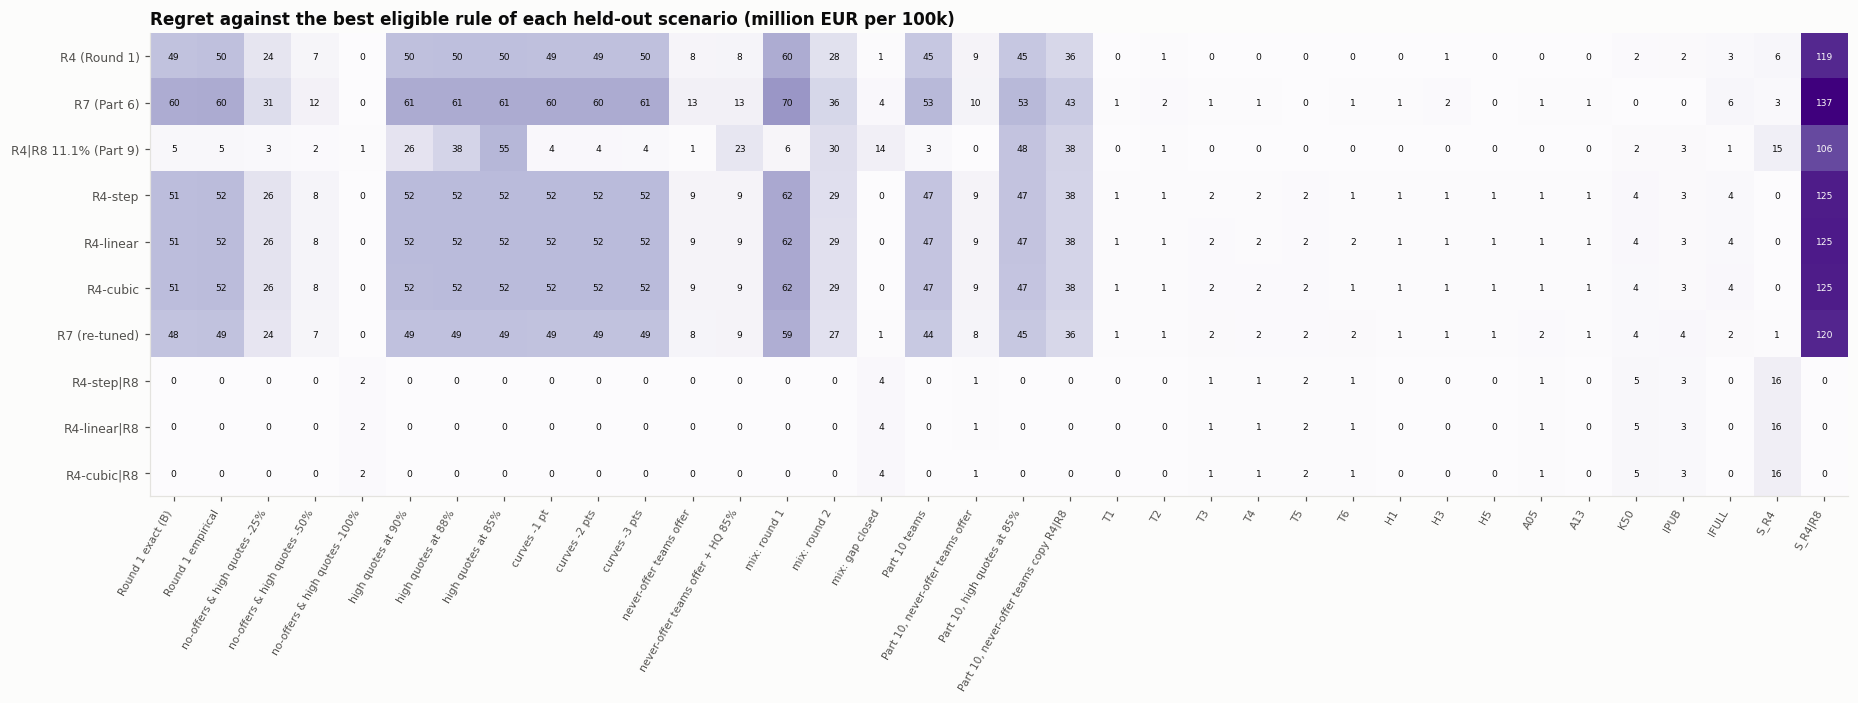

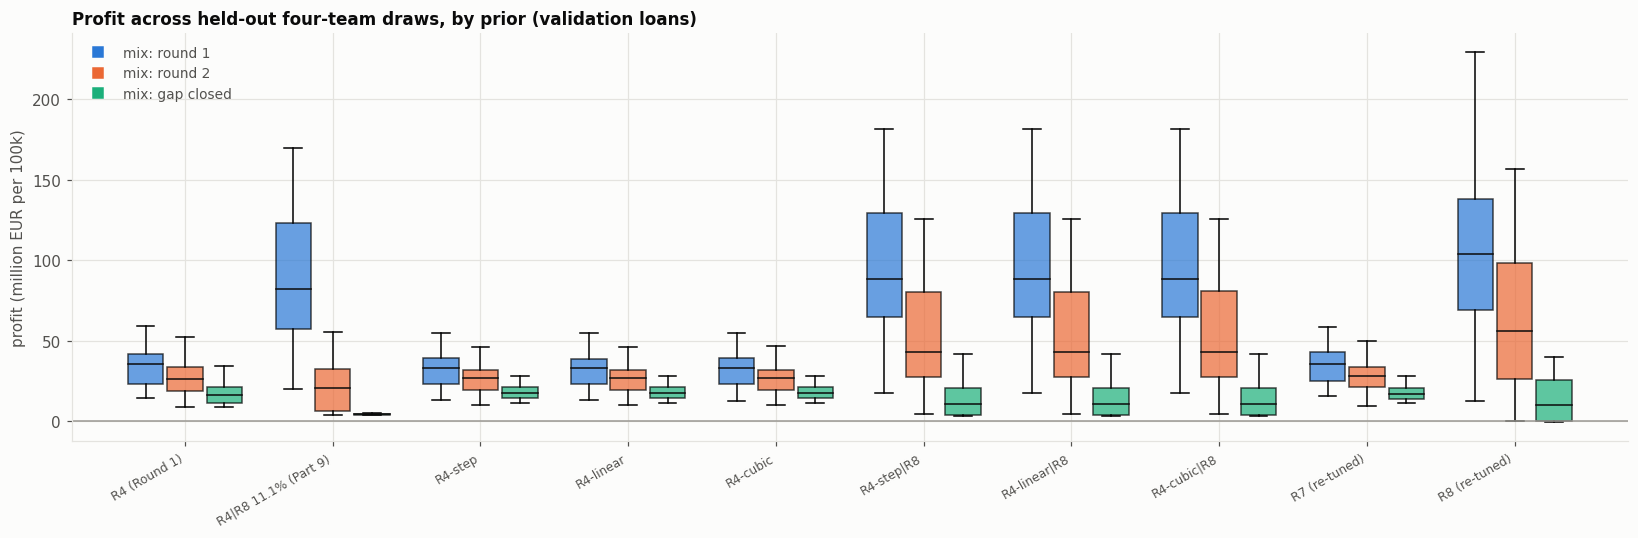

scenario,mix: round 1,mix: round 2,mix: gap closed
rule,,,
R4 (Round 1),+21.3M,+17.1M,+11.1M
R7 (Part 6),+15.8M,+13.9M,+11.1M
R8 89.5% (Part 9),+43.9M,-0.0M,-0.0M
R4|R8 11.1% (Part 9),+39.0M,+4.9M,+3.8M
R8|R4 11.1% (Part 9),+20.2M,+12.2M,+6.9M
R4-step,+20.1M,+17.4M,+12.4M
R4-linear,+20.0M,+17.5M,+12.5M
R4-cubic,+20.4M,+17.6M,+12.5M
R7 (re-tuned),+22.0M,+17.7M,+11.8M


In [17]:
fig, ax = plt.subplots(figsize=(17, 6.5))
r2.plot_regret_heatmap(regret, ax, "Regret against the best eligible rule of each held-out scenario (million EUR per 100k)")
fig.tight_layout()
save(fig, "fig28_stress_regret.png")
plt.show()

fig, ax = plt.subplots(figsize=(15, 5))
show = ["R4 (Round 1)", "R4|R8 11.1% (Part 9)", "R4-step", "R4-linear", "R4-cubic",
        "R4-step|R8", "R4-linear|R8", "R4-cubic|R8", "R7 (re-tuned)", "R8 (re-tuned)"]
r2.plot_mixture_spread(scores, show, ax, "Profit across held-out four-team draws, by prior (validation loans)")
fig.tight_layout()
save(fig, "fig29_mixture_spread.png")
plt.show()

p10 = r2.profit_table(scores[scores["group"] == "mixture"], stat=0.1)
display(money(p10).set_caption("10th percentile of profit over the 30 draws of each prior"))

**Findings: the stress tests.**

* **The R4|R8 hybrids have by far the smallest max regret: €15.7M**, against €106M for Part 9's
  R4|R8 11.1% and €119–137M for every rule without a high quote. They also have the highest
  weighted profit (€56.7M) and a positive worst case (+€0.3M).
* **Their max regret comes from S_R4** (both competitors copy R4, so no risky applicant is left
  uncontested): €4.2M against €19.8M for R4-linear.
* **The other rules' large regrets come from S_R4|R8** (both competitors quote 89.5% above 11.1%),
  where our 82% quote wins every risky applicant (€167M). That single scenario could be driving the
  choice; section 7b checks this.
* **High quotes cut to 85–90% leave the hybrid unchanged (€86.6M)**: its 82% is already below
  them. The same cut costs Part 9's 89.5% hybrid €50M.
* **When the pool is gone** (no-offers & high quotes −100%, gap-closed mixtures), the hybrid earns
  €3.3M and €14.9M, against €4.6M and €17.3M for R4. Quoting high to the risky half then costs
  €1–4M.
* **Retuning R4 alone (step, linear, cubic) does not help on held-out data:** €1–3M below the
  Round 1 R4 on the Round 1 market, because it quotes risky uncontested applicants a lower rate.
  It is ahead only in the contested scenarios (+€0.3–1.5M).

### 7b. Is the choice robust?

**Three questions:**

1. **Is it driven by one scenario?** The criteria are recomputed without S_R4|R8, and without any
   Part 7 scenario.
2. **How sensitive is the hybrid to its quote and its switch point?** The chosen hybrid is scored
   with other quotes and switch points in the key held-out scenarios.
3. **How often does it lose?** Over the 30 held-out draws of each prior, how often does the
   hybrid beat its own base rule (the same rule without the high quote), and by how much?

In [18]:
best_rule = crit.index[0]
base_name = best_rule.split("|")[0]
robust = {}
for label, cols in [("all held-out scenarios", list(profits.columns)),
                    ("without S_R4|R8", [c for c in profits.columns if c != "S_R4|R8"]),
                    ("without the Part 7 scenarios", [c for c in profits.columns if groups[c] != "part 7"])]:
    c_, _ = r2.criteria(profits[cols], ELIGIBLE)
    robust[label] = c_["max regret"]
display(money(pd.DataFrame(robust).sort_values("without the Part 7 scenarios"))
        .set_caption("Max regret with fewer scenarios"))

h = hybrid_choice[best_rule]
base = poly_rules[base_name]
variants = {f"quote {q:.1%}": r2.make_hybrid_rule(base, h["p_switch"], q, "above")
            for q in (0.78, 0.80, 0.82, 0.85, 0.875, 0.895)}
variants.update({f"switch {s:.1%}": r2.make_hybrid_rule(base, s, h["quote"], "above")
                 for s in RISKY_SWITCHES if s != h["p_switch"]})
variants[base_name] = base
KEY = ["Round 1 exact (B)", "Round 1 empirical", "high quotes at 85%", "never-offer teams offer",
       "no-offers & high quotes -100%", "mix: round 2", "mix: gap closed", "Part 10 teams", "S_R4"]
sens = r2.profit_table(r2.score_rules(variants, stress, pops))[KEY]
display(money(sens).set_caption(f"{best_rule} (switch {h['p_switch']:.1%}, quote {h['quote']:.0%}) "
                                "with other quotes and switch points"))

mix = scores[scores["group"] == "mixture"].pivot_table(index=["scenario", "draw"], columns="rule", values="profit")
diff = (mix[best_rule] - mix[base_name]).groupby(level="scenario")
display(pd.DataFrame({"hybrid ahead (share of draws)": diff.apply(lambda d: (d > 0).mean()),
                      "mean difference": diff.mean(), "worst difference": diff.min(),
                      "best difference": diff.max()})
        .style.format({"hybrid ahead (share of draws)": "{:.0%}", "mean difference": "{:+,.0f}",
                       "worst difference": "{:+,.0f}", "best difference": "{:+,.0f}"})
        .set_caption(f"{best_rule} minus {base_name}, per held-out mixture draw (EUR per 100k)"))

,all held-out scenarios,without S_R4|R8,without the Part 7 scenarios
rule,,,
R4-linear|R8,+15.7M,+15.7M,+3.9M
R4-step|R8,+15.7M,+15.7M,+3.9M
R4-cubic|R8,+15.7M,+15.7M,+3.9M
R4|R8 11.1% (Part 9),+105.9M,+54.7M,+54.7M
R7 (re-tuned),+120.3M,+58.6M,+58.6M
R4 (Round 1),+119.3M,+59.7M,+59.7M
R4-cubic,+125.0M,+61.5M,+61.5M
R4-step,+125.0M,+61.6M,+61.6M
R4-linear,+125.2M,+61.6M,+61.6M


scenario,Round 1 exact (B),Round 1 empirical,high quotes at 85%,never-offer teams offer,no-offers & high quotes -100%,mix: round 2,mix: gap closed,Part 10 teams,S_R4
rule,,,,,,,,,
quote 78.0%,+80.8M,+82.5M,+82.5M,+26.7M,+3.3M,+62.5M,+18.2M,+71.2M,+4.2M
quote 80.0%,+82.8M,+84.6M,+84.6M,+27.0M,+3.3M,+61.4M,+17.6M,+73.4M,+4.2M
quote 82.0%,+84.6M,+86.6M,+86.6M,+27.1M,+3.3M,+56.2M,+14.9M,+75.6M,+4.2M
quote 85.0%,+87.6M,+89.4M,+59.8M,+27.2M,+3.3M,+46.5M,+8.3M,+79.0M,+4.2M
quote 87.5%,+90.1M,+92.1M,+35.3M,+27.5M,+3.3M,+34.2M,+5.5M,+81.9M,+4.2M
quote 89.5%,+92.3M,+94.2M,+35.9M,+27.8M,+3.3M,+27.8M,+4.3M,+84.2M,+4.2M
switch 11.1%,+74.9M,+77.0M,+77.0M,+26.3M,+3.5M,+50.9M,+15.0M,+66.6M,+5.7M
switch 13.3%,+63.8M,+65.1M,+65.1M,+24.9M,+4.5M,+45.0M,+16.5M,+56.0M,+11.0M
switch 15.4%,+53.7M,+55.0M,+55.0M,+22.8M,+4.7M,+38.8M,+18.3M,+45.1M,+16.4M


,hybrid ahead (share of draws),mean difference,worst difference,best difference
scenario,,,,
mix: gap closed,23%,"-3,857,937","-17,223,311","+43,328,978"
mix: round 1,97%,"+61,527,425","-5,016,309","+137,655,342"
mix: round 2,77%,"+28,984,598","-15,439,876","+111,305,506"


**Findings.**

* **The choice does not hinge on S_R4|R8 or on Part 7.**
  * Without S_R4|R8, the hybrid's max regret is unchanged (€15.7M, set by S_R4), while every other
    rule's falls only to €55–70M.
  * Without any Part 7 scenario, the hybrid's max regret drops to €4M, against €55M or more for
    the others.
* **The quote is a trade-off with no free lunch:**
  * A higher quote earns more if Round 1 repeats: 89.5% would add €7.6M on the real Round 1
    market. But it loses most of its pool if the high quotes are cut to 85% (€36M against €87M)
    and in the round 2 mixtures (€28M against €56M).
  * A lower quote (78–80%) earns €5–6M more in the round 2 mixtures and €3M more in the
    gap-closed ones, but €2–4M less on Round 1.
  * **82% sits between the two.** Between 80% and 82% the difference is within €2–5M either way,
    a matter of judgement rather than evidence.
* **The switch at 8.7% beats every higher switch point unless the pool is gone.** Moving it
  to 11.1% or 13.3% costs €10–21M on Round 1 and €5–11M in the round 2 mixtures. It gains only
  where nobody is left uncontested: S_R4, no-offers & high quotes −100%, and the gap-closed mixtures
  (+€0.1–7M).
* **The hybrid is insurance with a premium:**
  * It beats its base rule in 97% of the Round 1-like draws and 77% of the round 2 draws, by
    +€61M and +€29M on average.
  * In the gap-closed draws it is behind 77% of the time, by €3.9M on average and up to €17M.

**Is the best rule's lead real?** We run a paired bootstrap (500 resamplings of the applicants) on
half B of Round 1, with the real offers and borrower types. It compares the rule with the smallest
max regret against R4 (Round 1) and against Part 9's R4|R8 11.1%. The other two hybrids are the
same rule on a different R4 variant, so comparing with them says nothing.

In [19]:
best_rule = crit.index[0]
runner_up = "R4|R8 11.1% (Part 9)"   # the best rule that is not the same hybrid on another R4 variant
b = pops["round1_B"]
market_b = r2.make_market(b["r1"], b["r2"], b["default"], pref=b["pref"])
per_app = {n: 2 * r2.market_profit(market_b, np.asarray(all_rules[n](b), dtype=float))
           for n in (best_rule, runner_up, "R4 (Round 1)")}
boot = pd.DataFrame({f"{best_rule} vs {o}": bootstrap_diff(per_app[best_rule], per_app[o])
                     for o in (runner_up, "R4 (Round 1)")}).T
display(boot.style.format({"estimate": "{:+,.0f}", "lower": "{:+,.0f}", "upper": "{:+,.0f}",
                           "share a > b": "{:.1%}"}))

,estimate,lower,upper,share a > b
R4-step|R8 vs R4|R8 11.1% (Part 9),"+4,571,688","+3,409,575","+5,735,032",100.0%
R4-step|R8 vs R4 (Round 1),"+48,706,380","+46,685,054","+50,891,249",100.0%


**Findings: the bootstrap.** On half B of Round 1, the chosen hybrid beats Part 9's R4|R8 11.1% by
**+€4.6M** (95% interval [+€3.4M, +€5.7M]) and the Round 1 R4 by **+€48.7M** ([+€46.7M, +€50.9M]),
in every resample. The lead is not noise in the defaults. It does assume the Round 1 competitors.

## 8. Every rule on the real Round 1 market

The exact counterfactual of Part 9, on all 100,000 Round 1 applicants with the real offers and
borrower types.

**Leakage.** The rules tuned in this part saw half A, through the empirical scenario and its
stresses (the offers and defaults of those applicants). Their profit on half A and on all 100,000
applicants is therefore partly in sample. **The honest figure is half B (× 2)**: its offers,
borrower types and defaults were never used in tuning. Half B does share the competitors of half
A, so it tests generalisation to new applicants, not to new competitors. That second question is
what the stresses, the mixtures and the Part 10 variants answer.

In [20]:
round1 = r2.round1_exact(all_rules, pops).sort_values("half B (held out) x2", ascending=False)
display(round1.style.format({"profit": "{:+,.0f}", "loans": "{:,.0f}", "share": "{:.1%}",
                             "profit per loan": "{:+,.0f}", "half A (tuning) x2": "{:+,.0f}",
                             "half B (held out) x2": "{:+,.0f}"}))

,profit,loans,share,profit per loan,half A (tuning) x2,half B (held out) x2
R8 89.5% (Part 9),"+118,926,850","20,328",20.3%,"+5,850","+116,396,800","+121,456,900"
R8 (re-tuned),"+105,850,000","21,122",21.1%,"+5,011","+103,516,000","+108,184,000"
R4-cubic|R8,"+82,287,243","40,297",40.3%,"+2,042","+79,901,473","+84,673,013"
R4-step|R8,"+82,285,820","40,571",40.6%,"+2,028","+79,929,939","+84,641,701"
R4-linear|R8,"+82,285,820","40,571",40.6%,"+2,028","+79,929,939","+84,641,701"
R4|R8 11.1% (Part 9),"+77,515,900","46,918",46.9%,"+1,652","+74,961,787","+80,070,013"
R8|R4 11.1% (Part 9),"+76,415,084","28,978",29.0%,"+2,637","+75,507,961","+77,322,207"
R7 (re-tuned),"+36,156,551","46,491",46.5%,+778,"+35,676,845","+36,636,258"
R4 (Round 1),"+35,004,134","55,568",55.6%,+630,"+34,072,948","+35,935,320"
R4-cubic,"+32,831,401","51,508",51.5%,+637,"+32,293,423","+33,369,380"


**Findings: the real Round 1 market.**

* **The chosen hybrid would have made €82.3M** (€84.6M on held-out half B, scaled), against our
  €35.0M and the winner's €73.3M, with 40.6% of the market at €2,028 per loan.
* **R8 at 89.5% would still have made more (€118.9M)**, because it was tuned on that market. The
  hybrid gives up about €37M of that in exchange for keeping its profit when competitors adapt.
* **Half A (tuning) and half B (held out) give similar figures** (€79.9M and €84.6M), so the
  tuning did not overfit the Round 1 defaults.

## 9. Market share against margin on safe applicants

The guidelines ask us to raise margins on safe applicants (below 11%) and to trace the trade-off
between market share and margin. The chosen rule's rates below 11% are shifted by −1 to +3 points
and scored in three held-out scenarios: the real Round 1 market, the round 2 mixtures and the
gap-closed mixtures.

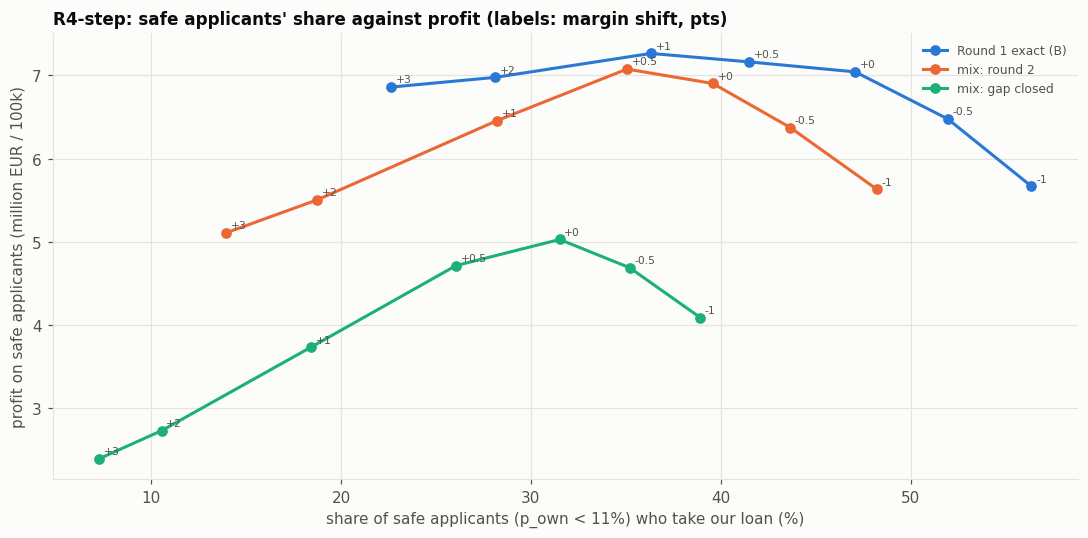

In [21]:
chosen_poly = best_rule.split("|")[0] if best_rule.split("|")[0] in poly_rules else "R4-linear"
base_for_tradeoff = poly_rules[chosen_poly]
shifts = [-0.01, -0.005, 0.0, 0.005, 0.01, 0.02, 0.03]
picked = [s for s in stress if s["name"] in ("Round 1 exact (B)", "mix: round 2", "mix: gap closed")]
tradeoff = r2.margin_tradeoff(base_for_tradeoff, picked, pops, shifts)
display(tradeoff.unstack(0).style.format("{:,.3f}", subset=pd.IndexSlice[:, ["safe share"]])
        .format("{:+,.0f}", subset=pd.IndexSlice[:, ["profit", "safe profit"]]))

fig, ax = plt.subplots(figsize=(10, 5))
r2.plot_tradeoff(tradeoff, ["Round 1 exact (B)", "mix: round 2", "mix: gap closed"], ax,
                 f"{chosen_poly}: safe applicants' share against profit (labels: margin shift, pts)")
fig.tight_layout()
save(fig, "fig30_share_margin.png")
plt.show()

**Findings: market share against margin.** Shifting the safe rates (below 11%) of the base rule
changes profit by **less than €0.6M**:

* **On the Round 1 market,** +0.5 to +1 point is best (+€0.1–0.2M). The safe share falls from 47%
  to 36–42%.
* **In the round 2 mixtures,** +0.5 point is best (+€0.2M).
* **In the gap-closed mixtures,** the tuned margin is best, and +1 point costs €1.3M.

**Decision: keep the tuned margins.** Raising them is a small bet on the competitors staying as
expensive as in Round 1. Market share is cheap to give up but earns little.

## 10. Retraining the default model on 200k loans

The diagnostic file gives the default of **all** 100,000 Round 1 applicants, whether or not they
borrowed from us. Their features are in `NewApplications_Lender3_Round1.csv`, so our own model
(spline logistic, public variables + `signal3`) can be refitted on 200,000 loans.

**Check, cross-fitted on Round 1.** Each fifth of the Round 1 applicants is predicted by a model
fitted on the 100k past loans plus the other four fifths. We compare it with the $p_{own}$ used
in Round 1 (fitted on the past loans only), on the same applicants, overall and by band, especially
above 11%.

cross-fitted in 5s


,applicants,default rate,mean p (100k),mean p (200k),gap (100k),gap (200k)
p_own,,,,,,
< 2.75%,"19,615",1.36%,1.29%,1.33%,+0.07%,+0.02%
2.75-4.5%,"10,482",3.60%,3.59%,3.68%,+0.00%,-0.08%
4.5-8%,"17,036",6.76%,6.16%,6.33%,+0.59%,+0.43%
8-11%,"12,625",9.42%,9.48%,9.56%,-0.06%,-0.15%
11-15%,"18,745",13.17%,12.98%,13.02%,+0.19%,+0.15%
15-20%,"10,519",17.26%,17.31%,17.22%,-0.05%,+0.05%
20-30%,"9,158",23.14%,23.86%,23.46%,-0.72%,-0.32%
>= 30%,"1,820",30.82%,35.19%,34.02%,-4.37%,-3.19%


,log-loss (100k),log-loss (200k),AUC (100k),AUC (200k)
value,0.2932,0.2930,0.7277,0.7279


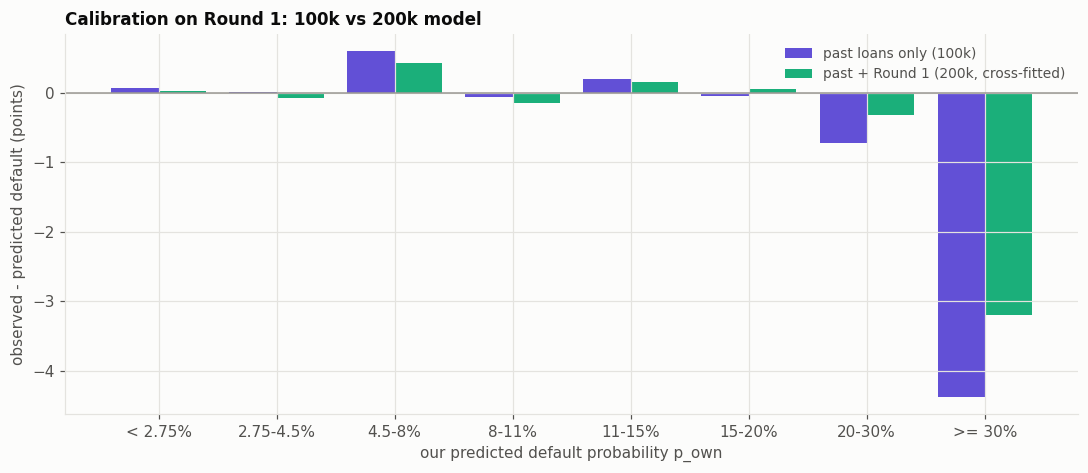

In [22]:
t0 = time.time()
cf = r2.crossfit_round1()
print(f"cross-fitted in {time.time() - t0:.0f}s")
calib, overall = r2.calibration_compare(cf)
display(calib.style.format({"applicants": "{:,.0f}", "default rate": "{:.2%}", "mean p (100k)": "{:.2%}",
                            "mean p (200k)": "{:.2%}", "gap (100k)": "{:+.2%}", "gap (200k)": "{:+.2%}"}))
display(overall.to_frame("value").T.style.format("{:.4f}"))

fig, ax = plt.subplots(figsize=(10, 4.4))
r2.plot_calibration(calib, ax)
fig.tight_layout()
save(fig, "fig31_calibration_200k.png")
plt.show()

In [23]:
round2_p = r2.predict_round2()
display(round2_p.describe(percentiles=[.5, .9, .99]).T.style.format("{:.4f}"))
print("correlation 100k vs 200k:", round(round2_p.corr().iloc[0, 1], 4))

,count,mean,std,min,50%,90%,99%,max
p_own_100k,100000.0000,0.0993,0.0774,0.0001,0.0862,0.2046,0.3344,0.4809
p_own_200k,100000.0000,0.0993,0.0754,0.0002,0.0875,0.2031,0.3247,0.4546


correlation 100k vs 200k: 0.9988


**Findings: retraining on 200k loans.**

* **Barely better overall:** log-loss 0.2932 → 0.2930, AUC 0.7277 → 0.7279, cross-fitted on Round 1.
* **Better calibrated where it was off:** above 30% risk the over-prediction falls from 4.4 to 3.2
  points, and from 0.7 to 0.3 point at 20–30%. Below 20% the two models are within 0.2 point of
  each other.
* **The Round 2 predictions of the two models correlate at 0.9988**, with the same mean (9.93%).
  50.3% of applicants are above the 8.7% switch with the 200k model, against 49.7% with the 100k
  model.

**Decision: price Round 2 with `p_own_200k`.** It uses twice the data and is better calibrated at
the top. The rule depends on $p_{own}$ only through the safe margins (where the models agree) and
the switch point, so the choice moves about 0.5% of applicants from one side of the switch to the
other.

## 11. The choice

In [24]:
display(money(crit[["max regret", "worst-case profit", "weighted profit"]]))
print("smallest max regret:", best_rule)
chosen_base = best_rule.split("|")[0]
if chosen_base in poly_rules:
    hybrid = None
    if best_rule in hybrid_choice:
        h = hybrid_choice[best_rule]
        hybrid = {"p_switch": h["p_switch"], "quote": h["quote"], "high_side": "above"}
    path = r2.save_round2_rule(best_rule, fits[chosen_base.replace("R4-", "")], hybrid,
                               notes=f"Chosen in Part 11 (analysis/round_2_rule.ipynb): smallest max regret "
                                     f"over the held-out stress tests among the eligible rules.")
    print("saved to", path)
    reloaded = r2.load_round2_rule()
    same = np.allclose(np.nan_to_num(reloaded(b).to_numpy(), nan=-1),
                       np.nan_to_num(np.asarray(all_rules[best_rule](b), dtype=float), nan=-1))
    print("reloaded rule gives the same rates:", same)

,max regret,worst-case profit,weighted profit
rule,,,
R4-step|R8,+15.7M,+0.3M,+56.7M
R4-linear|R8,+15.7M,+0.3M,+56.7M
R4-cubic|R8,+15.7M,+0.2M,+56.7M
R4|R8 11.1% (Part 9),+105.9M,+0.3M,+43.6M
R4 (Round 1),+119.3M,-2.0M,+25.9M
R7 (re-tuned),+120.3M,-1.2M,+26.3M
R4-step,+125.0M,-2.5M,+24.4M
R4-cubic,+125.0M,-2.7M,+24.4M
R4-linear,+125.2M,-2.6M,+24.4M


smallest max regret: R4-step|R8
saved to /Users/kenzachaabouni/Documents/MSC_M2/intro-finance/LendingGame_Lender3_Round1/Lending-Game/data/pricing/final_rule_round2.json
reloaded rule gives the same rates: True


In [25]:
f, h = fits[chosen_base.replace("R4-", "")], hybrid_choice[best_rule]
lo, hi = np.r_[0.0, f["edges"]], np.r_[f["edges"], 0.5]
display(pd.DataFrame([{"p_own": f"{100 * a:.1f}-{100 * b:.1f}%",
                       "rate": (f"break-even + {100 * f['coefs'][k, 0]:.2f} pts" if b <= h["p_switch"] + 1e-12
                                else f"{100 * h['quote']:.0f}% flat")}
                      for k, (a, b) in enumerate(zip(lo, hi))]).set_index("p_own")
        .rename_axis(f"{best_rule}: the Round 2 rule").T)

R4-step|R8: the Round 2 rule,0.0-1.2%,1.2-2.8%,2.8-4.5%,4.5-6.4%,6.4-8.7%,8.7-11.1%,11.1-13.3%,13.3-15.4%,15.4-20.6%,20.6-50.0%
rate,break-even + 3.00 pts,break-even + 2.75 pts,break-even + 2.25 pts,break-even + 3.25 pts,break-even + 3.25 pts,82% flat,82% flat,82% flat,82% flat,82% flat


**The Round 2 rule: R4-step|R8.**

* **Below $p_{own} = 8.7\%$ (about half of the applicants):** break-even plus the margin tuned on
  contested markets: 3.0, 2.75, 2.25, 3.25 and 3.25 points over the five safest deciles.
* **From 8.7%:** a flat **82%** quote.
* **No offer when 82% is below our break-even:** $be(p_{own}) \ge 0.82$, i.e.
  $p_{own} \ge 0.82 / 1.82 = 45.05\%$, where the expected profit $(1-p)\,0.82 - p$ is negative
  (10 Round 2 applicants).
* **Rate floor 0.5%;** $p_{own}$ from the model refitted on 200k loans (`p_own_200k`).

**Why this rule:**

* **The smallest max regret by far** (€15.7M, next best €106M), the highest weighted profit
  (€56.7M per 100k) and a positive worst case. This holds without the Part 7 scenarios too.
* **It would have made €82M in Round 1** (the winner made €73M), €4.6M more than Part 9's hybrid,
  significantly.
* **It survives the adaptations we can foresee:** high quotes cut to 85% cost it nothing, and it
  keeps €27M if the never-offer teams start offering (R4: €19M).
* **Its cost:** if every competitor lends to the risky half at moderate rates, it earns €1–4M less
  than R4 on average, and up to €17M less in the worst draws.

The rule is saved in `data/pricing/final_rule_round2.json`. Rebuild it with
`r2.load_round2_rule()` and apply it to `p_own_200k` in
`data/predictions/applications_round2_own.csv`.